EXPERIMENT 8: MATCHED FILTERING, ISI AND EYE DIAGRAMS

Basic Parameters
----------------
Number of bits       : 5000
Samples/symbol       : 8
Roll-off factor      : 0.35
Filter span          : 8 symbols
SNR                  : 10 dB

First 20 bits:
[0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0]

First 20 BPSK symbols:
[-1  1 -1 -1 -1  1 -1 -1 -1  1 -1 -1 -1 -1  1 -1  1  1  1 -1]

MANDATORY DELAY VALIDATION
Number of RRC filter taps : 66
Single RRC filter delay   : 32 samples
Total cascade delay      : 64 samples
Detection starts AFTER   : 64 samples
BER after delay removal  : 0.0

Delay Measurement Test
----------------------
Expected cascade delay : 64 samples
Measured cascade peak  : 65 samples
Delay validation: CHECK


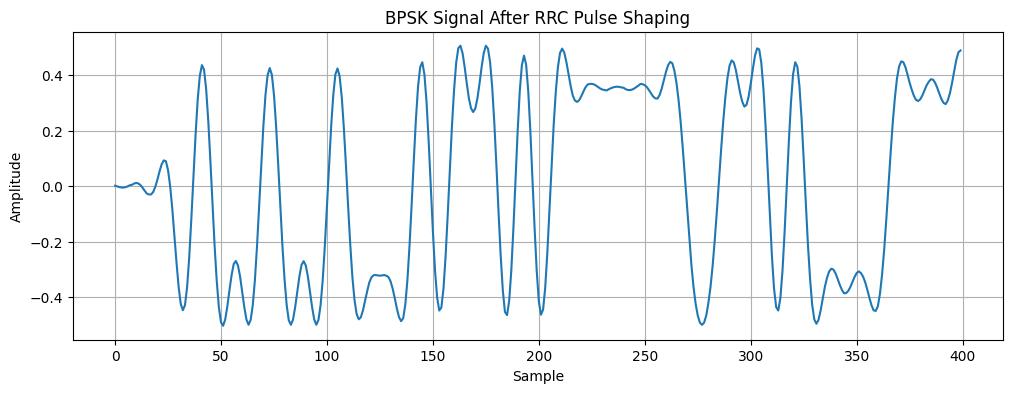

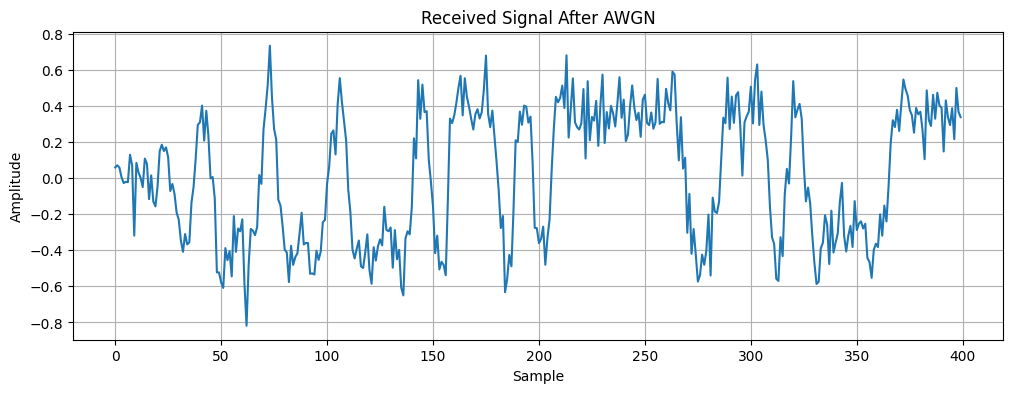

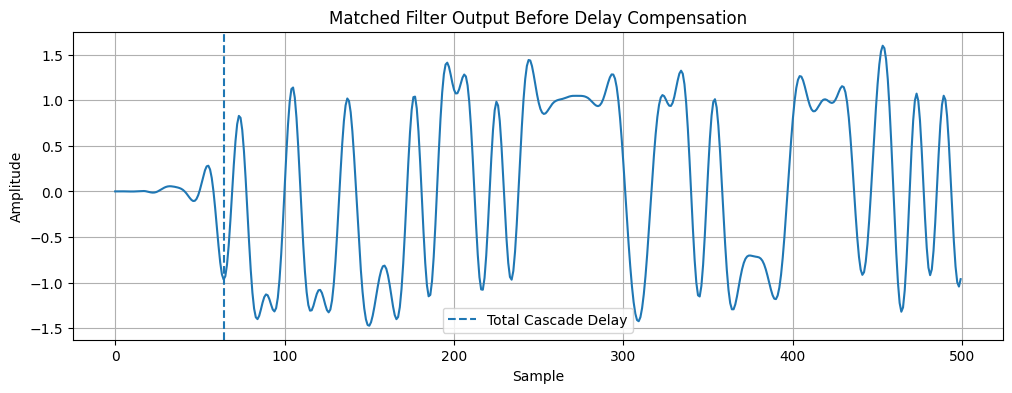

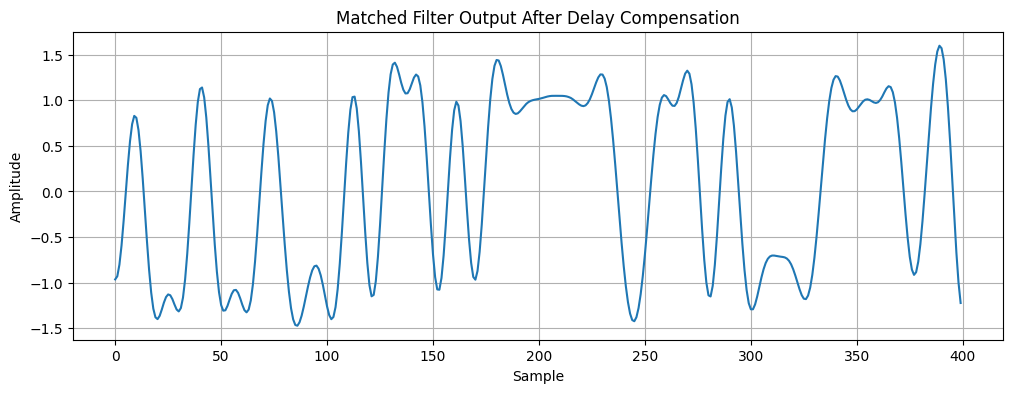

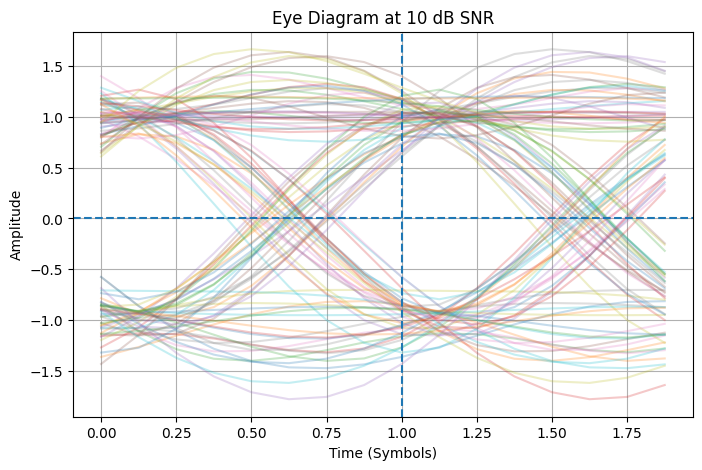

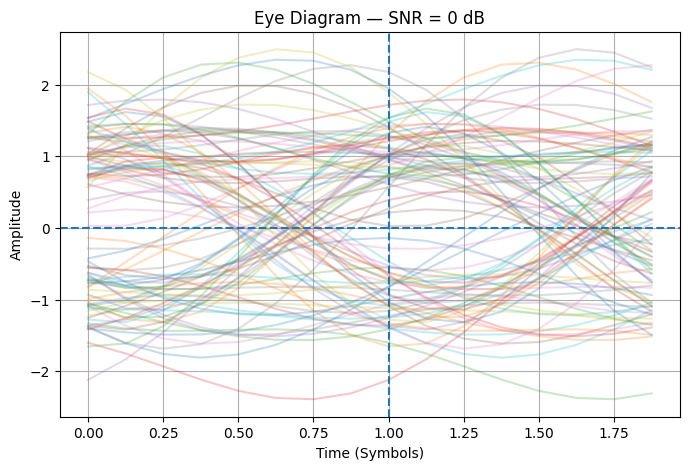

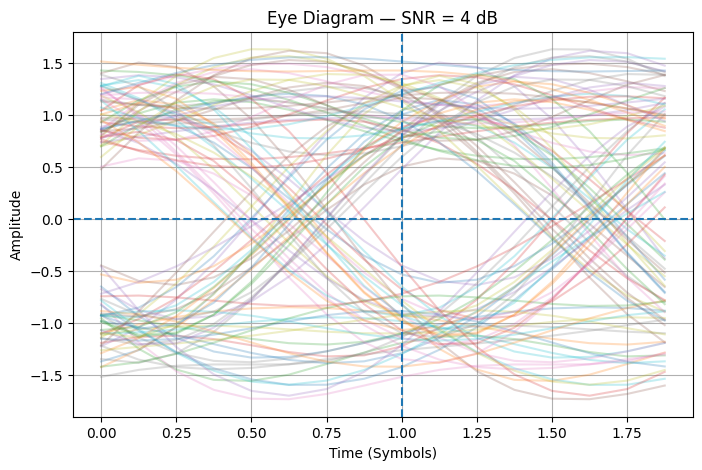

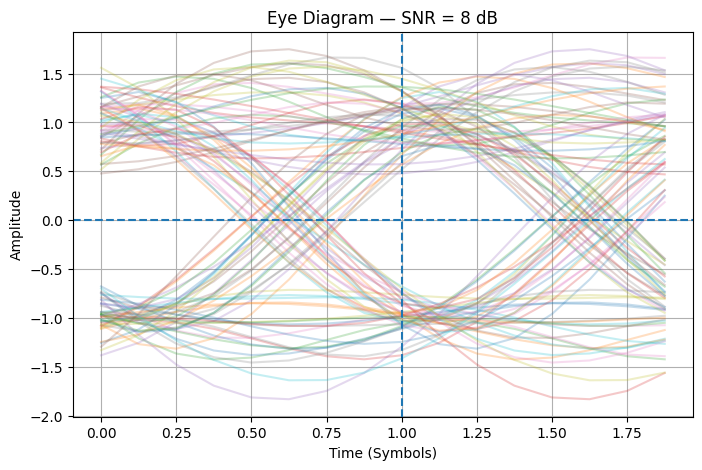

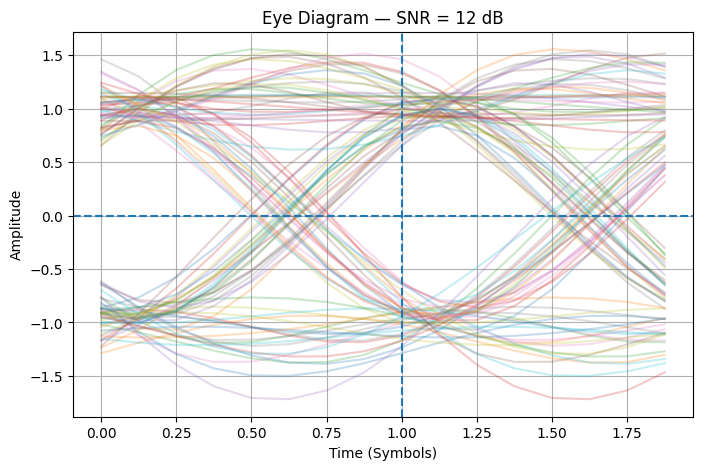

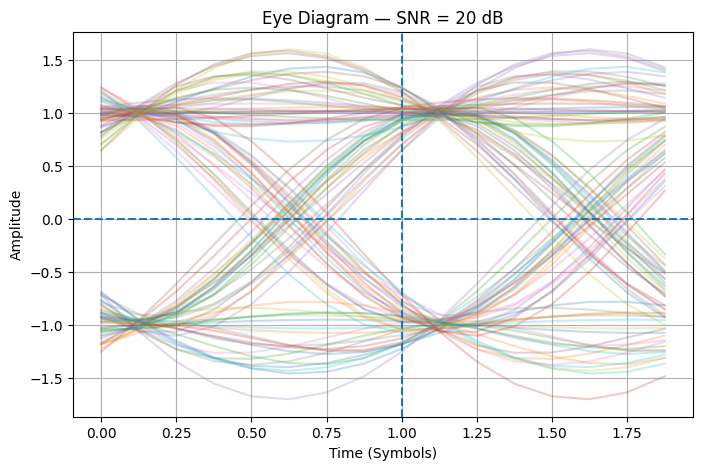

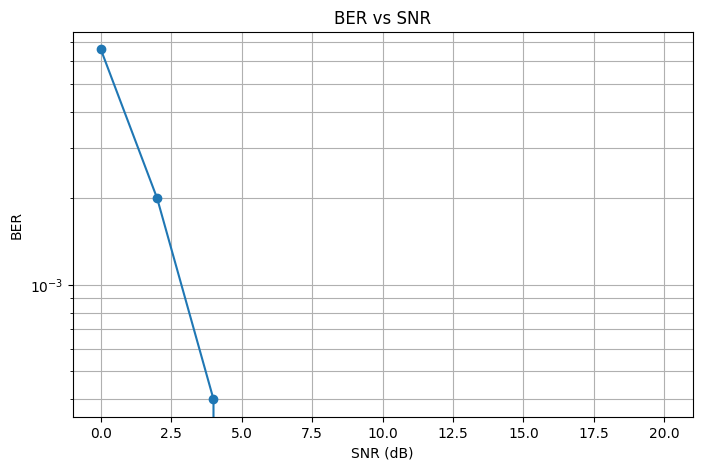

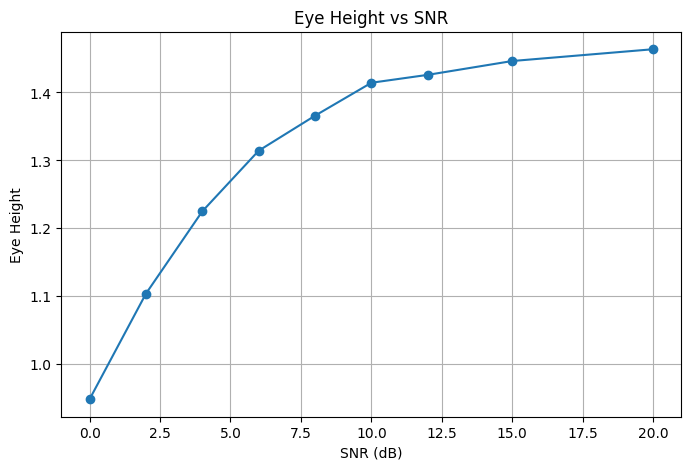


SNR RESULTS
--------------------------------------------------
   SNR(dB)            BER        Eye Height
         0       0.006600            0.9483
         2       0.002000            1.1038
         4       0.000400            1.2250
         6       0.000000            1.3143
         8       0.000000            1.3658
        10       0.000000            1.4143
        12       0.000000            1.4260
        15       0.000000            1.4463
        20       0.000000            1.4637


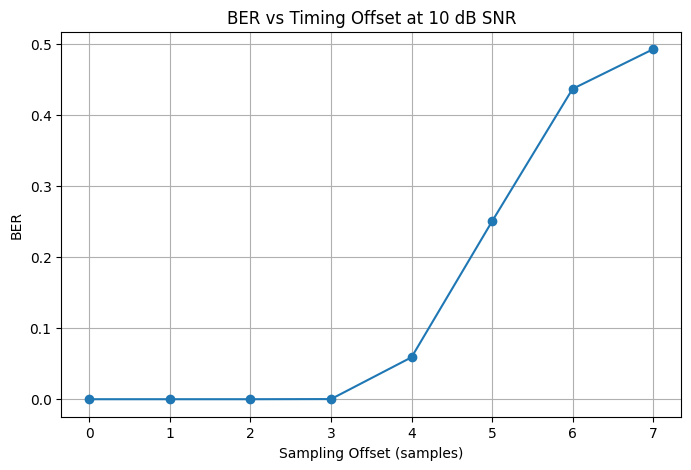


OPTIMUM SAMPLING INSTANT
Offset 0: BER = 0.000000
Offset 1: BER = 0.000000
Offset 2: BER = 0.000000
Offset 3: BER = 0.000200
Offset 4: BER = 0.059000
Offset 5: BER = 0.250200
Offset 6: BER = 0.436600
Offset 7: BER = 0.492400

Optimum sampling offset = 0 samples
Minimum BER = 0.0


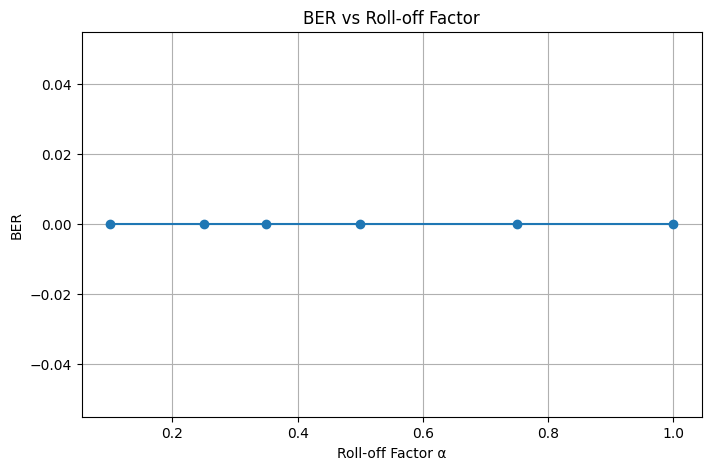

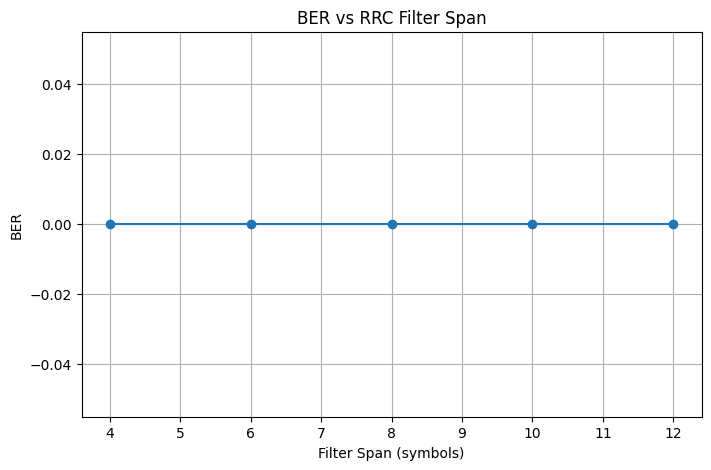


MULTIPATH ISI
Multipath channel coefficients: [1.   0.   0.   0.45 0.   0.   0.2 ]
RRC filter delay: 32 samples
RRC cascade delay: 64 samples


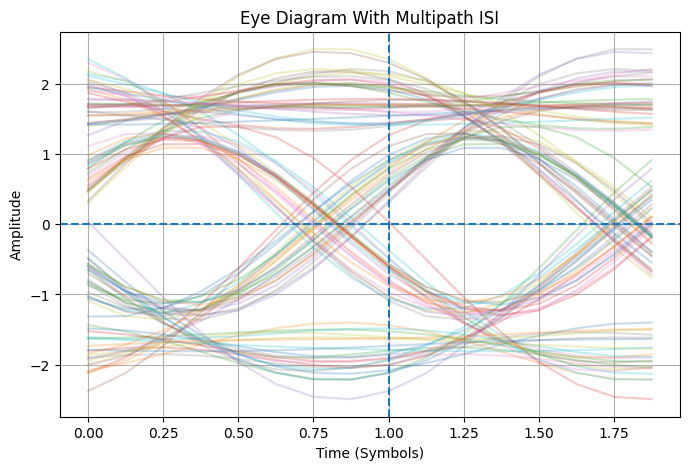

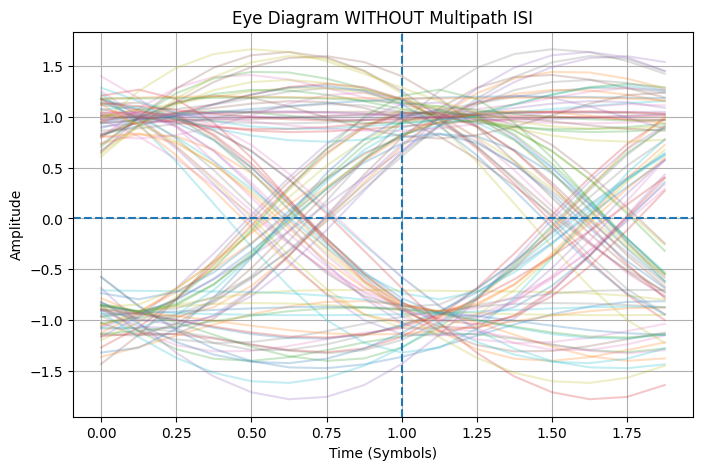

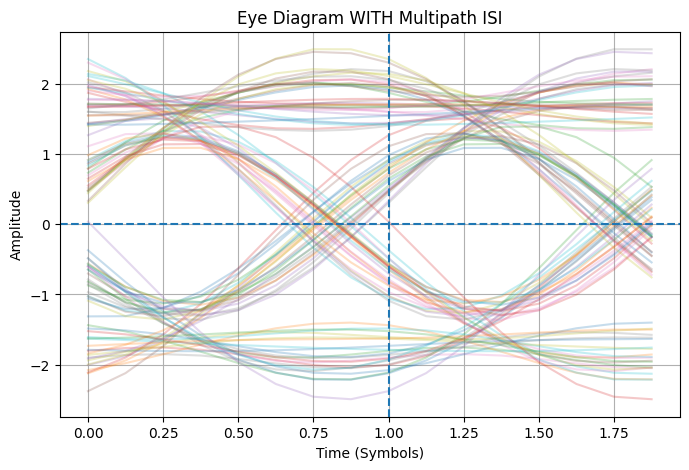


BER without multipath = 0.0
BER with multipath    = 0.0004


EXPERIMENT 8 — FINAL SUMMARY

1. Matched filtering completed.
2. RRC pulse shaping completed.
3. AWGN channel implemented.
4. Total cascade delay verified.
5. Symbol detection performed AFTER delay compensation.
6. Eye diagrams generated.
7. Eye height vs SNR generated.
8. BER vs SNR generated.
9. BER vs timing offset generated.
10. Roll-off variation tested.
11. Filter span variation tested.
12. Multipath ISI introduced and analyzed.


IMPORTANT THEORETICAL OBSERVATIONS
-----------------------------------
• Increasing SNR generally improves the eye opening and reduces BER.
• Incorrect timing moves the sampling instant away from the eye center and increases BER.
• RRC roll-off controls excess bandwidth and time-domain pulse characteristics.
• Increasing filter span reduces truncation effects but increases complexity and latency.
• Multipath creates delayed replicas and produces ISI.
• Matched filtering maximizes SNR at the s

In [ ]:
# ================================================================
# EXPERIMENT 8 — MATCHED FILTERING, ISI AND EYE DIAGRAMS
# ================================================================
# BPSK + RRC Pulse Shaping + AWGN + Matched Filtering
# No Communication Toolbox required
# Google Colab / Python
#
# REQUIRED VISUALIZATIONS:
# 1. Transmit / matched-filter output
# 2. Eye diagrams
# 3. Eye height versus SNR
# 4. BER versus timing offset
# 5. SNR variation
# 6. Roll-off variation
# 7. Filter span variation
# 8. Multipath ISI
#
# MANDATORY VALIDATION:
# Confirm total cascade delay and ensure symbol detection
# occurs only AFTER delay compensation.
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ================================================================
# 1. BASIC PARAMETERS
# ================================================================

N_BITS = 5000
SPS = 8
ROLL_OFF = 0.35
SPAN = 8
SNR_DB = 10

print("=" * 65)
print("EXPERIMENT 8: MATCHED FILTERING, ISI AND EYE DIAGRAMS")
print("=" * 65)

print("\nBasic Parameters")
print("----------------")
print("Number of bits       :", N_BITS)
print("Samples/symbol       :", SPS)
print("Roll-off factor      :", ROLL_OFF)
print("Filter span          :", SPAN, "symbols")
print("SNR                  :", SNR_DB, "dB")


# ================================================================
# 2. GENERATE RANDOM BITS AND BPSK SYMBOLS
# ================================================================

bits = np.random.randint(0, 2, N_BITS)

# BPSK:
# 0 -> -1
# 1 -> +1

symbols = 2 * bits - 1

print("\nFirst 20 bits:")
print(bits[:20])

print("\nFirst 20 BPSK symbols:")
print(symbols[:20])


# ================================================================
# 3. ROOT RAISED COSINE FILTER
# ================================================================

def rrc_filter(beta, span, sps):

    # Number of taps
    N = span * sps

    # Make number of taps odd
    if N % 2 == 0:
        N = N + 1

    t = np.arange(-N//2, N//2 + 1) / sps

    h = np.zeros(len(t))

    for i, ti in enumerate(t):

        # t = 0
        if abs(ti) < 1e-12:

            h[i] = 1 + beta * (4/np.pi - 1)

        # t = +/-1/(4*beta)
        elif beta > 0 and abs(abs(4*beta*ti) - 1) < 1e-12:

            h[i] = (
                beta / np.sqrt(2)
                *
                (
                    (1 + 2/np.pi) *
                    np.sin(np.pi/(4*beta))
                    +
                    (1 - 2/np.pi) *
                    np.cos(np.pi/(4*beta))
                )
            )

        # General case
        else:

            numerator = (
                np.sin(np.pi * ti * (1-beta))
                +
                4 * beta * ti *
                np.cos(np.pi * ti * (1+beta))
            )

            denominator = (
                np.pi * ti *
                (1 - (4*beta*ti)**2)
            )

            h[i] = numerator / denominator

    # Normalize energy
    h = h / np.sqrt(np.sum(h**2))

    return h


# ================================================================
# 4. UPSAMPLING
# ================================================================

def upsample_symbols(symbols, sps):

    x = np.zeros(len(symbols) * sps)

    x[::sps] = symbols

    return x


# ================================================================
# 5. AWGN
# ================================================================

def add_awgn(signal, snr_db):

    signal_power = np.mean(signal ** 2)

    snr_linear = 10 ** (snr_db / 10)

    noise_power = signal_power / snr_linear

    noise = np.sqrt(noise_power) * np.random.randn(len(signal))

    return signal + noise


# ================================================================
# 6. TRANSMITTER
# ================================================================

def transmit_bpsk(bits, beta, span, sps, snr_db):

    symbols = 2 * bits - 1

    upsampled = upsample_symbols(symbols, sps)

    h = rrc_filter(beta, span, sps)

    # RRC pulse shaping
    tx = np.convolve(upsampled, h)

    # AWGN
    rx = add_awgn(tx, snr_db)

    return symbols, upsampled, tx, rx, h


# ================================================================
# 7. MATCHED FILTER
# ================================================================

def matched_filter(rx, h):

    # Matched filter is time-reversed RRC
    h_mf = h[::-1]

    y = np.convolve(rx, h_mf)

    return y


# ================================================================
# 8. DELAY COMPENSATION
# ================================================================

def compensate_delay(y, h):

    single_filter_delay = (len(h) - 1) // 2

    total_delay = 2 * single_filter_delay

    # IMPORTANT:
    # Detection is performed ONLY after removing total delay
    y_compensated = y[total_delay:]

    return (
        y_compensated,
        single_filter_delay,
        total_delay
    )


# ================================================================
# 9. SYMBOL DETECTION
# ================================================================

def detect_symbols(y, sps, offset=0):

    samples = y[offset::sps]

    detected_bits = np.where(
        samples >= 0,
        1,
        0
    )

    return detected_bits, samples


# ================================================================
# 10. BER CALCULATION
# ================================================================

def calculate_ber(tx_bits, detected_bits):

    L = min(
        len(tx_bits),
        len(detected_bits)
    )

    return np.mean(
        tx_bits[:L] != detected_bits[:L]
    )


# ================================================================
# 11. EYE DIAGRAM FUNCTION
# ================================================================

def eye_diagram(
    signal,
    sps,
    span_symbols=2,
    max_traces=100,
    title="Eye Diagram"
):

    samples_per_trace = span_symbols * sps

    traces = []

    # Shift by one symbol for each trace
    for i in range(max_traces):

        start = i * sps

        end = start + samples_per_trace

        if end <= len(signal):

            traces.append(
                signal[start:end]
            )

    traces = np.array(traces)

    time_axis = np.arange(
        samples_per_trace
    ) / sps

    plt.figure(figsize=(8,5))

    for trace in traces:

        plt.plot(
            time_axis,
            trace,
            alpha=0.25
        )

    # Center of 2-symbol window
    plt.axvline(
        1,
        linestyle='--'
    )

    plt.axhline(
        0,
        linestyle='--'
    )

    plt.xlabel("Time (Symbols)")
    plt.ylabel("Amplitude")

    plt.title(title)

    plt.grid(True)

    plt.show()

    return traces


# ================================================================
# 12. COMPLETE SYSTEM SIMULATION
# ================================================================

def simulate(
    bits,
    beta,
    span,
    sps,
    snr_db
):

    # Transmitter
    symbols, upsampled, tx, rx, h = transmit_bpsk(
        bits,
        beta,
        span,
        sps,
        snr_db
    )

    # Matched filter
    y = matched_filter(
        rx,
        h
    )

    # Delay compensation
    y_compensated, filter_delay, total_delay = (
        compensate_delay(
            y,
            h
        )
    )

    # Detect symbols AFTER delay compensation
    detected_bits, samples = detect_symbols(
        y_compensated,
        sps,
        0
    )

    # BER
    ber = calculate_ber(
        bits,
        detected_bits
    )

    return {
        "symbols": symbols,
        "upsampled": upsampled,
        "tx": tx,
        "rx": rx,
        "matched": y,
        "compensated": y_compensated,
        "samples": samples,
        "detected": detected_bits,
        "h": h,
        "filter_delay": filter_delay,
        "total_delay": total_delay,
        "ber": ber
    }


# ================================================================
# 13. BASIC SIMULATION
# ================================================================

result = simulate(
    bits,
    ROLL_OFF,
    SPAN,
    SPS,
    SNR_DB
)

print("\n" + "=" * 65)
print("MANDATORY DELAY VALIDATION")
print("=" * 65)

print(
    "Number of RRC filter taps :",
    len(result["h"])
)

print(
    "Single RRC filter delay   :",
    result["filter_delay"],
    "samples"
)

print(
    "Total cascade delay      :",
    result["total_delay"],
    "samples"
)

print(
    "Detection starts AFTER   :",
    result["total_delay"],
    "samples"
)

print(
    "BER after delay removal  :",
    result["ber"]
)


# ================================================================
# 14. IMPULSE RESPONSE DELAY TEST
# ================================================================

h = result["h"]

impulse = np.zeros(500)

impulse[0] = 1

cascade_response = np.convolve(
    np.convolve(
        impulse,
        h
    ),
    h[::-1]
)

measured_delay = np.argmax(
    np.abs(cascade_response)
)

expected_delay = result["total_delay"]

print("\nDelay Measurement Test")
print("----------------------")

print(
    "Expected cascade delay :",
    expected_delay,
    "samples"
)

print(
    "Measured cascade peak  :",
    measured_delay,
    "samples"
)

if measured_delay == expected_delay:

    print("Delay validation: PASS")

else:

    print("Delay validation: CHECK")


# ================================================================
# 15. TRANSMITTED SIGNAL
# ================================================================

plt.figure(figsize=(12,4))

plt.plot(
    result["tx"][:400]
)

plt.title(
    "BPSK Signal After RRC Pulse Shaping"
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.grid(True)

plt.show()


# ================================================================
# 16. RECEIVED SIGNAL
# ================================================================

plt.figure(figsize=(12,4))

plt.plot(
    result["rx"][:400]
)

plt.title(
    "Received Signal After AWGN"
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.grid(True)

plt.show()


# ================================================================
# 17. MATCHED FILTER OUTPUT
# ================================================================

plt.figure(figsize=(12,4))

plt.plot(
    result["matched"][:500]
)

plt.axvline(
    result["total_delay"],
    linestyle='--',
    label="Total Cascade Delay"
)

plt.title(
    "Matched Filter Output Before Delay Compensation"
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.legend()

plt.grid(True)

plt.show()


# ================================================================
# 18. MATCHED FILTER OUTPUT AFTER DELAY REMOVAL
# ================================================================

plt.figure(figsize=(12,4))

plt.plot(
    result["compensated"][:400]
)

plt.title(
    "Matched Filter Output After Delay Compensation"
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.grid(True)

plt.show()


# ================================================================
# 19. EYE DIAGRAM — BASIC
# ================================================================

eye_diagram(
    result["compensated"],
    SPS,
    span_symbols=2,
    max_traces=100,
    title=f"Eye Diagram at {SNR_DB} dB SNR"
)


# ================================================================
# 20. EYE DIAGRAMS FOR DIFFERENT SNRs
# ================================================================

snr_list = [
    0,
    4,
    8,
    12,
    20
]

for snr in snr_list:

    r = simulate(
        bits,
        ROLL_OFF,
        SPAN,
        SPS,
        snr
    )

    eye_diagram(
        r["compensated"],
        SPS,
        span_symbols=2,
        max_traces=100,
        title=f"Eye Diagram — SNR = {snr} dB"
    )


# ================================================================
# 21. SNR VARIATION
# ================================================================

snr_values = [
    0, 2, 4, 6, 8,
    10, 12, 15, 20
]

bers_snr = []

eye_heights = []


for snr in snr_values:

    r = simulate(
        bits,
        ROLL_OFF,
        SPAN,
        SPS,
        snr
    )

    bers_snr.append(
        r["ber"]
    )

    samples = r["samples"]

    positive = samples[
        samples > 0
    ]

    negative = samples[
        samples < 0
    ]

    if (
        len(positive) > 0 and
        len(negative) > 0
    ):

        upper = np.percentile(
            positive,
            10
        )

        lower = np.percentile(
            negative,
            90
        )

        eye_height = upper - lower

    else:

        eye_height = 0

    eye_heights.append(
        eye_height
    )


# ================================================================
# 22. BER vs SNR
# ================================================================

plt.figure(figsize=(8,5))

plt.semilogy(
    snr_values,
    bers_snr,
    'o-'
)

plt.xlabel("SNR (dB)")
plt.ylabel("BER")

plt.title(
    "BER vs SNR"
)

plt.grid(
    True,
    which="both"
)

plt.show()


# ================================================================
# 23. EYE HEIGHT vs SNR
# ================================================================

plt.figure(figsize=(8,5))

plt.plot(
    snr_values,
    eye_heights,
    'o-'
)

plt.xlabel("SNR (dB)")
plt.ylabel("Eye Height")

plt.title(
    "Eye Height vs SNR"
)

plt.grid(True)

plt.show()


# ================================================================
# 24. PRINT SNR RESULTS
# ================================================================

print("\nSNR RESULTS")
print("-" * 50)

print(
    f"{'SNR(dB)':>10}"
    f"{'BER':>15}"
    f"{'Eye Height':>18}"
)

for snr, ber, eh in zip(
    snr_values,
    bers_snr,
    eye_heights
):

    print(
        f"{snr:>10}"
        f"{ber:>15.6f}"
        f"{eh:>18.4f}"
    )


# ================================================================
# 25. BER vs TIMING OFFSET
# ================================================================

timing_snr = 10

timing_result = simulate(
    bits,
    ROLL_OFF,
    SPAN,
    SPS,
    timing_snr
)

y = timing_result[
    "compensated"
]

timing_offsets = np.arange(
    SPS
)

timing_ber = []


for offset in timing_offsets:

    detected, samples = detect_symbols(
        y,
        SPS,
        offset
    )

    ber = calculate_ber(
        bits,
        detected
    )

    timing_ber.append(
        ber
    )


# ================================================================
# 26. BER vs TIMING OFFSET GRAPH
# ================================================================

plt.figure(figsize=(8,5))

plt.plot(
    timing_offsets,
    timing_ber,
    'o-'
)

plt.xlabel(
    "Sampling Offset (samples)"
)

plt.ylabel("BER")

plt.title(
    f"BER vs Timing Offset at {timing_snr} dB SNR"
)

plt.xticks(
    timing_offsets
)

plt.grid(True)

plt.show()


# ================================================================
# 27. AUTOMATIC OPTIMUM SAMPLING INSTANT
# ================================================================

best_index = np.argmin(
    timing_ber
)

print("\n" + "=" * 65)
print("OPTIMUM SAMPLING INSTANT")
print("=" * 65)

for offset, ber in zip(
    timing_offsets,
    timing_ber
):

    print(
        f"Offset {offset}: BER = {ber:.6f}"
    )

print(
    "\nOptimum sampling offset =",
    timing_offsets[best_index],
    "samples"
)

print(
    "Minimum BER =",
    timing_ber[best_index]
)


# ================================================================
# 28. ROLL-OFF FACTOR VARIATION
# ================================================================

rolloffs = [
    0.10,
    0.25,
    0.35,
    0.50,
    0.75,
    1.00
]

rolloff_ber = []


for beta in rolloffs:

    r = simulate(
        bits,
        beta,
        SPAN,
        SPS,
        10
    )

    rolloff_ber.append(
        r["ber"]
    )


plt.figure(figsize=(8,5))

plt.plot(
    rolloffs,
    rolloff_ber,
    'o-'
)

plt.xlabel(
    "Roll-off Factor α"
)

plt.ylabel("BER")

plt.title(
    "BER vs Roll-off Factor"
)

plt.grid(True)

plt.show()


# ================================================================
# 29. FILTER SPAN VARIATION
# ================================================================

spans = [
    4,
    6,
    8,
    10,
    12
]

span_ber = []


for span_value in spans:

    r = simulate(
        bits,
        ROLL_OFF,
        span_value,
        SPS,
        10
    )

    span_ber.append(
        r["ber"]
    )


plt.figure(figsize=(8,5))

plt.plot(
    spans,
    span_ber,
    'o-'
)

plt.xlabel(
    "Filter Span (symbols)"
)

plt.ylabel("BER")

plt.title(
    "BER vs RRC Filter Span"
)

plt.grid(True)

plt.show()


# ================================================================
# 30. MULTIPATH ISI CHANNEL
# ================================================================

def multipath_channel(signal):

    # Direct path + delayed echoes
    #
    # Delays:
    # 0 samples
    # 3 samples
    # 6 samples

    channel_h = np.array([
        1.0,
        0.0,
        0.0,
        0.45,
        0.0,
        0.0,
        0.20
    ])

    output = np.convolve(
        signal,
        channel_h
    )

    return output, channel_h


# ================================================================
# 31. TRANSMIT THROUGH MULTIPATH CHANNEL
# ================================================================

symbols_isi, upsampled_isi, tx_isi, rx_isi, h_isi = (
    transmit_bpsk(
        bits,
        ROLL_OFF,
        SPAN,
        SPS,
        15
    )
)

# Multipath
rx_multipath, channel_h = (
    multipath_channel(
        tx_isi
    )
)

# AWGN
rx_multipath = add_awgn(
    rx_multipath,
    15
)

# Matched filter
y_multipath = matched_filter(
    rx_multipath,
    h_isi
)

# Remove RRC cascade delay
y_multipath_comp, fd_isi, td_isi = (
    compensate_delay(
        y_multipath,
        h_isi
    )
)


print("\n" + "=" * 65)
print("MULTIPATH ISI")
print("=" * 65)

print(
    "Multipath channel coefficients:",
    channel_h
)

print(
    "RRC filter delay:",
    fd_isi,
    "samples"
)

print(
    "RRC cascade delay:",
    td_isi,
    "samples"
)


# ================================================================
# 32. EYE DIAGRAM WITH MULTIPATH ISI
# ================================================================

eye_diagram(
    y_multipath_comp,
    SPS,
    span_symbols=2,
    max_traces=100,
    title="Eye Diagram With Multipath ISI"
)


# ================================================================
# 33. NO ISI vs ISI EYE DIAGRAM
# ================================================================

eye_diagram(
    result["compensated"],
    SPS,
    span_symbols=2,
    max_traces=100,
    title="Eye Diagram WITHOUT Multipath ISI"
)

eye_diagram(
    y_multipath_comp,
    SPS,
    span_symbols=2,
    max_traces=100,
    title="Eye Diagram WITH Multipath ISI"
)


# ================================================================
# 34. BER WITH MULTIPATH ISI
# ================================================================

detected_isi, samples_isi = detect_symbols(
    y_multipath_comp,
    SPS,
    0
)

ber_isi = calculate_ber(
    bits,
    detected_isi
)

print(
    "\nBER without multipath =",
    result["ber"]
)

print(
    "BER with multipath    =",
    ber_isi
)


# ================================================================
# 35. FINAL SUMMARY
# ================================================================

print("\n")
print("=" * 65)
print("EXPERIMENT 8 — FINAL SUMMARY")
print("=" * 65)

print(
    "\n1. Matched filtering completed."
)

print(
    "2. RRC pulse shaping completed."
)

print(
    "3. AWGN channel implemented."
)

print(
    "4. Total cascade delay verified."
)

print(
    "5. Symbol detection performed AFTER delay compensation."
)

print(
    "6. Eye diagrams generated."
)

print(
    "7. Eye height vs SNR generated."
)

print(
    "8. BER vs SNR generated."
)

print(
    "9. BER vs timing offset generated."
)

print(
    "10. Roll-off variation tested."
)

print(
    "11. Filter span variation tested."
)

print(
    "12. Multipath ISI introduced and analyzed."
)

print("\n")
print("IMPORTANT THEORETICAL OBSERVATIONS")
print("-----------------------------------")

print(
    "• Increasing SNR generally improves the eye opening "
    "and reduces BER."
)

print(
    "• Incorrect timing moves the sampling instant away "
    "from the eye center and increases BER."
)

print(
    "• RRC roll-off controls excess bandwidth and "
    "time-domain pulse characteristics."
)

print(
    "• Increasing filter span reduces truncation effects "
    "but increases complexity and latency."
)

print(
    "• Multipath creates delayed replicas and produces ISI."
)

print(
    "• Matched filtering maximizes SNR at the sampling instant."
)

print(
    "• Symbol detection must occur only after removal "
    "of the total TX + RX filter delay."
)

print("\nExperiment completed successfully!")